# Photonic Quantum-Enhanced Knowledge Distillation (PQKD): a reproduction

This notebook reproduces and tests *Photonic Quantum-Enhanced Knowledge Distillation* (Chen, Yu, et al., [arXiv:2603.14898](https://arxiv.org/abs/2603.14898), 2026).

It is written as a scientific argument:
1. what the paper claims;
2. how we test it;
3. what reproduces;
4. what survives fair controls.

**How it runs**

| What | Where it comes from |
|---|---|
| Live evidence (under 10 min on a CPU laptop; the last cell prints the measured runtime) | Code in sections 2–6 and 11 executes live: data loading, known-answer checks of every mechanism, and a small end-to-end distillation experiment |
| Full experiments | Loaded from committed, programmatically generated result files in `results/`: 3 seeds × 30 epochs per arm, about 80 CPU-hours |

Each loaded table names its source file and the sweep that produced it. Every number shown below is computed in this notebook from those files.

**Labels used throughout:**
- **Partial RED-tier run:** MNIST only, 30 epochs (paper: 100), 3 seeds (paper: 5), CPU.
- **Simulated:** all photonic results come from MerLin simulations; no hardware was used.
- **Live smoke-scale:** the live experiment in section 6 illustrates mechanisms only; it is not evidence about accuracy rankings.

In [1]:
import contextlib
import copy
import io
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

PAPER_DIR = Path.cwd().resolve()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError(f"Run this notebook from papers/photonic_QKD (cwd is {PAPER_DIR})")
REPO_ROOT = PAPER_DIR.parents[1]
RESULTS = PAPER_DIR / "results"
for path in (str(PAPER_DIR), str(REPO_ROOT)):
    if path not in sys.path:
        sys.path.insert(0, path)

from lib.data import load_splits  # noqa: E402
from lib.models import (  # noqa: E402
    ThreeBlockCNN,
    iso_parameter_widths,
    teacher_parameter_formula,
    trainable_parameter_count,
)
from lib.photonic import TimeBinFeatureMap, fock_space_size  # noqa: E402
from lib.runner import train_and_evaluate  # noqa: E402
from runtime_lib.config import deep_update, load_config  # noqa: E402

# One colour per kind of conditioning source, used in every figure.
COLOURS = {
    "photonic": "#2a78d6",  # photonic z (paper-faithful, θ near identity)
    "sampled": "#eb6834",   # photonic z in a stochastic (mixing) regime
    "exact": "#1baf7a",     # photonic z from exact MerLin probabilities + autograd
    "classical": "#6b6a64", # non-photonic z or no z
}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def load_result(name):
    # Committed result files written by utils/analyze_s4.py, analyze_s6.py,
    # compare_phase5.py, feature_stability.py and export_sweep_summary.py.
    return json.loads((RESULTS / name).read_text())


def fmt(entry, digits=2):
    if entry is None:
        return "—"
    if entry.get("std") is None:
        return f"{entry['mean']:.{digits}f}"
    return f"{entry['mean']:.{digits}f} ± {entry['std']:.{digits}f}"


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


NOTEBOOK_START = time.perf_counter()
print("torch", torch.__version__, "| paper dir:", PAPER_DIR.name)

torch 2.10.0+cu128 | paper dir: photonic_QKD


## 1. Problem statement and paper claim

**Problem.** Compress a CNN student while distilling knowledge from a larger teacher.

**PQKD's proposal.** Replace each selected convolution kernel by a *dictionary convolution*:
- the layer learns only a few spatial basis filters;
- its channel-mixing tensor is generated from a global conditioning vector **z(θ)**;
- z(θ) is built from the click statistics of a programmable 16-mode photonic interferometer whose beam-splitter angles θ are trained gradient-free with SPSA.

**Claims in scope** (MNIST, conv1 + conv2 compressed):

| ID | Claim (paper) | Paper evidence |
|---|---|---|
| A (C1) | At about 1.5× compression, PQKD matches or exceeds the teacher (val 99.09 vs 99.07 %) | Table 1, Fig. 3 |
| B (C3, C9, C6) | The photonic module is what makes this work: learning θ improves the SPSA objective (Table 1 "photonic Δ"), and the photonic feature adds a large test-accuracy gain δ over z = 0 (Fig. 4) | Table 1, Fig. 4 |
| C (C6, C7) | That gain degrades with fewer shots as δ∞ − k/√S, and EMA smoothing of z raises δ∞ | Fig. 4 |

**Falsifiable research question.** Under an identical architecture, data and training budget, does a *photonic* conditioning vector give higher test accuracy than (i) a *non-photonic* vector, or (ii) a plain student with the same number of trainable parameters?

**Evidence that would weaken the claims** (predeclared before any run, in `LOG.md`):
- If a fixed random z gives the same accuracy as the photonic z, or freezing θ changes nothing, claim B is weakened.
- If a dense KD student at the same trainable budget matches or beats PQKD, claim A is weakened as an advantage.
- If shot noise and EMA affect a classical noisy z the same way, claim C is not photonic-specific.
- A difference only counts when the mean paired per-seed difference exceeds the s.d. of that difference across seeds.

## 2. Data, splits, metrics, and evaluation protocol

**Data.** MNIST from torchvision, MD5-verified, stored under `data/photonic_QKD/`.

**Splits.**
- The paper's split indices are not published.
- The 45,000/5,000 train/validation split is a seeded permutation (`split_seed = 0`) of the canonical training set.
- The canonical 10,000-image test set is held out.

**Preprocessing.** Pixels scaled to [0, 1]; no normalisation or augmentation.

**Metrics.**
- **Primary:** final-epoch **test** accuracy.
- **Also reported:** validation accuracy and cross-entropy, the paper's metrics.

**Protocol rules.**
- Hyperparameters are paper values. Unreported ones (the SPSA step sizes) were chosen on **validation** data only, by predeclared grids (section 9).
- The test split is used only for final evaluation.
- The method itself (SPSA on θ) optimises a validation objective, the paper's design. Validation accuracy is therefore optimistically biased for PQKD, which is why test accuracy is primary.

In [2]:
defaults = load_config(PAPER_DIR / "configs" / "defaults.json")
print(f"device used by every run: {defaults['device']} (configs/defaults.json); CUDA available: {torch.cuda.is_available()}")
data_cfg = copy.deepcopy(defaults)
data_cfg["data_root"] = str(REPO_ROOT / "data")
splits = load_splits(data_cfg)

table(
    ["split", "images", "label counts (0–9)"],
    [
        [name, len(getattr(splits, name).tensors[1]),
         " ".join(str(int(c)) for c in torch.bincount(getattr(splits, name).tensors[1], minlength=10))]
        for name in ("train", "val", "test")
    ],
)
image = splits.train.tensors[0]
print("source:", splits.description["source"].split(" under ")[0])
print("split rule:", splits.description["splits"]["rule"])
print(f"pixel range: [{float(image.min()):.1f}, {float(image.max()):.1f}], shape {tuple(image.shape[1:])}")

device used by every run: cpu (configs/defaults.json); CUDA available: False


| split | images | label counts (0–9) |
|---|---|---|
| train | 45000 | 4387 5050 4506 4627 4384 4031 4449 4645 4411 4510 |
| val | 5000 | 479 593 503 512 469 460 484 536 485 479 |
| test | 10000 | 980 1135 1032 1010 982 892 958 1028 974 1009 |

source: torchvision mnist canonical train/test
split rule: seeded permutation of canonical train: first train_size -> train, next val_size -> val; canonical test kept
pixel range: [0.0, 1.0], shape (1, 28, 28)


## 3. Method in brief

**Dictionary convolution** (paper Eqs. 6–7). For a layer with C_out × C_in channels and k × k kernels:

$$W[o,i] \;=\; g_o \sum_{r=1}^{R} M[o,i,r]\, B_r, \qquad \mathrm{vec}(M) = A\, z, \qquad A_{jk} \sim \mathcal N(0, 1/d).$$

- The basis B (R × k × k), a per-output-channel gain g and a bias are trained.
- A is a fixed random matrix.
- z ∈ ℝ^d (d = 512) is the conditioning vector.
- A compressed layer therefore has R·k² + 2·C_out trainable parameters. This accounting is inferred: it is the only one that reproduces the paper's compression factors (section 4).

**Photonic conditioning vector.**
- A 16-mode loop interferometer of nearest-neighbour beam splitters BS(θ) (3 tilings × 15 = 45 angles) receives a fixed input photon pattern.
- Threshold detectors record S shots, giving 16-bit click patterns b.
- Each pattern is split into two 8-bit halves, and their histograms are concatenated and standardised:

$$\tilde z(\theta) = [\,h_1;\, h_2\,] \in \mathbb R^{512}, \qquad z = (\tilde z - \mu)/\sigma .$$

**Training** (each epoch):
1. **SPSA on θ:** 10 updates per epoch, θ ← θ − a_k ĝ_k, using two perturbed evaluations of a validation KD objective J per update.
2. **One Adam epoch on the student**, with the KD loss
$$\mathcal L = \lambda\,\mathrm{CE}(y, s) + (1-\lambda)\,\tau^2\,\mathrm{KL}\big(\mathrm{softmax}(t/\tau)\,\|\,\mathrm{softmax}(s/\tau)\big), \quad \tau = 3,\ \lambda = 0.5.$$
3. Optionally, an EMA of z across epochs (β = 0.9).

The paper initialises θ = 0.

## 4. Known-answer sanity checks

Each check has an answer known in advance. These are component validations, not reproduction results.

In [3]:
# 4a. Parameter accounting reproduces the paper's architecture and compression factor.
teacher = ThreeBlockCNN(1, (64, 128, 128), 0.25)
student = ThreeBlockCNN(
    1, (64, 128, 128), 0.25, compressed=(True, True, False), ranks=(4, 4, 4),
    feature_dim=512, mixing="feature", generator=torch.Generator().manual_seed(0),
)
theta_dim = 45
teacher_params = trainable_parameter_count(teacher)
student_params = trainable_parameter_count(student) + theta_dim
dense_widths = iso_parameter_widths(student_params, 1, 128)
dense_params = trainable_parameter_count(ThreeBlockCNN(1, dense_widths, 0.25))
assert teacher_params == teacher_parameter_formula((64, 128, 128)) == 224_394
table(
    ["model", "trainable parameters", "expected"],
    [
        ["teacher (64,128,128)", f"{teacher_params:,}", "≈ 2.25e5 (paper)"],
        ["PQKD student (dictionary conv1+conv2, R=4) + θ", f"{student_params:,}", "—"],
        ["overall compression C_x = teacher / student", f"{teacher_params / student_params:.3f}", "1.50 (paper Table 1)"],
        [f"B1 dense KD student, widths {dense_widths}", f"{dense_params:,}", f"within ±5% of PQKD ({100 * (dense_params / student_params - 1):+.1f}%)"],
    ],
)

| model | trainable parameters | expected |
|---|---|---|
| teacher (64,128,128) | 224,394 | ≈ 2.25e5 (paper) |
| PQKD student (dictionary conv1+conv2, R=4) + θ | 149,439 | — |
| overall compression C_x = teacher / student | 1.502 | 1.50 (paper Table 1) |
| B1 dense KD student, widths (52, 104, 104) | 148,626 | within ±5% of PQKD (-0.5%) |

In [4]:
# 4b. z = 0 is a degenerate control: it makes every compressed kernel exactly zero.
torch.manual_seed(0)
for name, z in (("z = 0", torch.zeros(512)), ("random z", torch.randn(512))):
    norms = [float(conv.kernel(z).detach().norm()) for conv in student.convs[:2]]
    print(f"{name:9s} -> kernel norms of compressed conv1, conv2: {norms[0]:.4f}, {norms[1]:.4f}")

z = 0     -> kernel norms of compressed conv1, conv2: 0.0000, 0.0000
random z  -> kernel norms of compressed conv1, conv2: 11.6300, 17.0219


**Observation:** z = 0 zeroes every compressed kernel. **Claim impact:** the paper's Fig. 4 measures its photonic gain δ against z = 0. That baseline is a *broken network* (chance accuracy), not a "no-photonics" student. Any working z, photonic or not, will show a large δ. Section 6 tests this live.

In [5]:
# 4c. The photonic sampler (MerLin, 16 modes, 4 photons as in Phase 4 / P0).
input_state = [1, 0, 0, 0] * 4
feature_map = TimeBinFeatureMap(16, theta_dim=45, input_state=input_state)
print(f"Fock space: {fock_space_size(16, 4):,} states (8 photons would be {fock_space_size(16, 8):,})")

zero_theta = torch.zeros(45)
p0 = feature_map.outcome_probabilities(zero_theta)
print(f"θ = 0: largest outcome probability = {float(p0.max()):.6f} "
      f"(pattern {feature_map.layer.output_keys[int(p0.argmax())]}) -> the circuit is a fixed permutation")

rng = torch.Generator().manual_seed(0)
draws_zero = torch.stack([feature_map.raw_feature(zero_theta, 200, rng) for _ in range(20)])
print(f"θ = 0, S = 200: max |difference| between 20 shot draws = {float((draws_zero - draws_zero[0]).abs().max()):.2e}")

theta_mixing = (torch.rand(45, generator=torch.Generator().manual_seed(1)) * 2 - 1) * math.pi
variances = {}
for shots in (25, 200):
    draws = torch.stack([feature_map.raw_feature(theta_mixing, shots, rng) for _ in range(300)])
    variances[shots] = float(draws.var(dim=0).sum())
print(f"random θ: total feature variance S=25: {variances[25]:.4f}, S=200: {variances[200]:.4f}, "
      f"ratio {variances[25] / variances[200]:.2f} (multinomial theory: 200/25 = 8)")

Fock space: 3,876 states (8 photons would be 490,314)
θ = 0: largest outcome probability = 1.000000 (pattern (1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0)) -> the circuit is a fixed permutation
θ = 0, S = 200: max |difference| between 20 shot draws = 0.00e+00


random θ: total feature variance S=25: 0.0694, S=200: 0.0085, ratio 8.20 (multinomial theory: 200/25 = 8)


**Observation:**
- At θ = 0, every shot gives the same click pattern, so z has **no shot noise at all**.
- At random θ, the feature variance scales as 1/S, as multinomial sampling predicts.

**Claim impact:** the paper starts SPSA at θ = 0. Its shot-noise and EMA claims (C) can only act if θ moves far from 0. Section 11 tests this regime directly.

In [6]:
# 4d. θ = 0 is an exact stationary point of the photonic feature's gradient.
weights = torch.randn(512, generator=torch.Generator().manual_seed(2), dtype=torch.float64)
feature_map.angles.requires_grad_(True)
for name, theta in (("θ = 0", zero_theta), ("random θ", theta_mixing)):
    with torch.no_grad():
        feature_map.angles.copy_(theta.to(torch.float64))
    feature_map.angles.grad = None
    (feature_map.differentiable_exact_feature() * weights).sum().backward()
    print(f"{name:9s}: |d objective / d θ| = {float(feature_map.angles.grad.norm()):.3e}")
feature_map.angles.requires_grad_(False)

θ = 0    : |d objective / d θ| = 0.000e+00
random θ : |d objective / d θ| = 9.034e-01


Parameter containing:
tensor([ 1.6187, -1.3866, -0.6090,  1.4746, -2.9576,  1.8841, -0.6463,  1.5983,
         0.4367, -0.3847,  0.8714,  0.1550,  1.1474, -1.2243, -0.2290, -0.2828,
         0.4554, -0.0126,  2.7463,  0.9776, -1.1699, -1.8974, -0.5266, -1.3551,
        -1.0067,  0.1504,  1.8728,  1.7076, -3.0711,  1.9475,  0.8776,  2.9800,
         2.0736, -2.8624, -2.9871, -1.5153,  2.7587, -0.5233,  1.3445, -1.4599,
         3.0826, -1.3292,  2.3560,  0.0372, -1.6550], dtype=torch.float64)

**Observation:** the gradient of any objective of z with respect to θ is exactly zero at θ = 0.

**Inference:** a gradient-trained photonic generator initialised like the paper never moves. Section 11 confirms this in full training: arm N2, with ‖θ‖ = 0.00 after 30 epochs on every seed.

## 5. Pipeline walkthrough

Every experiment is one call to `lib.runner.train_and_evaluate(cfg, run_dir)`, the same entry point the repository CLI uses. A configuration is built in three layers:
1. `configs/defaults.json`, holding the paper hyperparameters;
2. an experiment overlay such as `configs/pqkd_4ph_merlin.json`;
3. explicit overrides.

The run writes `run.log`, `run_status.json`, `config_snapshot.json` and `metrics.json`. The cell below shows the settings that distinguish the arms used next.

In [7]:
ARMS = {
    # name: (config overlay, colour family)
    "PQKD (photonic z, 4 photons)": ("pqkd_4ph_merlin.json", "photonic"),
    "B3f fixed random z": ("baseline_random_fixed_classical.json", "classical"),
    "B0 z = 0": ("baseline_zero_classical.json", "classical"),
}


def resolved_config(overlay=None, overrides=None):
    cfg = copy.deepcopy(defaults)
    if overlay is not None:
        cfg = deep_update(cfg, load_config(PAPER_DIR / "configs" / overlay))
    return deep_update(cfg, copy.deepcopy(overrides or {}))


rows = []
for name, (overlay, _) in ARMS.items():
    cfg = resolved_config(overlay)
    source = cfg["conditioning"]["source"]
    rows.append([
        name, cfg["task"], cfg["student"]["variant"], source,
        cfg["conditioning"]["shots"] if source == "photonic" else "—",
        cfg["conditioning"]["ema"]["enabled"],
        f"a={cfg['spsa']['a']}, c={cfg['spsa']['c']}" if source == "photonic" else "not used",
        sum(cfg["photonic"]["input_state"]) if source == "photonic" else "none",
    ])
table(["arm", "task", "variant", "z source", "shots S", "EMA", "SPSA", "photons"], rows)

| arm | task | variant | z source | shots S | EMA | SPSA | photons |
|---|---|---|---|---|---|---|---|
| PQKD (photonic z, 4 photons) | student | dictionary | photonic | 200 | True | a=0.01, c=0.2 | 4 |
| B3f fixed random z | student | dictionary | random_fixed | — | True | not used | none |
| B0 z = 0 | student | dictionary | zero | — | True | not used | none |

## 6. Small live experiment (smoke-scale)

**Question tested live.** Does the photonic z behave differently from a *non-photonic* z, and what does the paper's z = 0 control measure?

**Setup (live, smoke-scale):**
- **Teacher:** the stored S1 seed-0 teacher, `models/teacher_mnist_s1_seed0/teacher.pt`. It was trained for 30 epochs on the 45k training split and is committed so the notebook does not retrain it (~1 MB).
- **Students:** three students that differ **only** in their conditioning source, for seeds 0 and 1.
- **Budget:** 3,000 training images, 1,000 validation and 1,000 test images, 2 epochs, 1 SPSA validation batch instead of 4, to keep the notebook under 10 minutes on a CPU.

At this scale absolute accuracies are below MNIST's ceiling and noisy, so this run cannot rank photonic vs random z. Only effects much larger than the seed spread are interpretable here; the full-scale ranking comes from section 8.

Runs are written to `outdir/notebook_live/`, which is git-ignored.

In [8]:
LIVE_BUDGET = {
    "dataset": {"max_train_samples": 3000, "max_eval_samples": 1000},
    "training": {"epochs": 2},
    "spsa": {"val_batches": 1},
    "data_root": str(REPO_ROOT / "data"),
    "logging": {"level": "info", "save_feature_trace": True},
}
LIVE_SEEDS = (0, 1)


def run_quietly(cfg, run_dir):
    # The runner mirrors its run.log to stderr; keep the full log on disk only.
    with contextlib.redirect_stderr(io.StringIO()):
        train_and_evaluate(cfg, run_dir)
live_dir = PAPER_DIR / "outdir" / "notebook_live" / time.strftime("run_%Y%m%d-%H%M%S")
live_dir.mkdir(parents=True)

# Stored S1 teacher (seed 0): 30 epochs on the full 45k training split, same split seed and widths.
TEACHER_PATH = PAPER_DIR / "models" / "teacher_mnist_s1_seed0" / "teacher.pt"
teacher_record = torch.load(TEACHER_PATH, map_location="cpu", weights_only=False)
s1_teacher = load_result("s1_teacher_mnist.json")["rows"][0]
print(f"teacher: {TEACHER_PATH.relative_to(PAPER_DIR)} | dataset {teacher_record['dataset']}, "
      f"split_seed {teacher_record['split_seed']}, widths {teacher_record['widths']}, best epoch {teacher_record['best_epoch']} "
      f"| S1 seed-0 test accuracy {s1_teacher['best_checkpoint.test_accuracy']['values'][0]:.2f} %")

live_start = time.perf_counter()
live = {name: {} for name in ARMS}
for seed in LIVE_SEEDS:
    for name, (overlay, _) in ARMS.items():
        start = time.perf_counter()
        cfg = resolved_config(overlay, LIVE_BUDGET)
        cfg["seed"] = seed
        cfg["teacher"]["checkpoint"] = str(TEACHER_PATH)
        run_dir = live_dir / f"{overlay.removesuffix('.json')}_seed{seed}"
        run_quietly(cfg, run_dir)
        status = json.loads((run_dir / "run_status.json").read_text())
        assert status["status"] == "COMPLETED", status["error"]
        live[name][seed] = json.loads((run_dir / "metrics.json").read_text())
        print(f"seed {seed} | {name:30s} | test {live[name][seed]['final_evaluation']['test_accuracy']:6.2f} % "
              f"({time.perf_counter() - start:.0f} s)")
print(f"live students: {time.perf_counter() - live_start:.0f} s")

teacher: models/teacher_mnist_s1_seed0/teacher.pt | dataset mnist, split_seed 0, widths [64, 128, 128], best epoch 26 | S1 seed-0 test accuracy 99.29 %


seed 0 | PQKD (photonic z, 4 photons)   | test  68.30 % (40 s)


seed 0 | B3f fixed random z             | test  60.30 % (25 s)


seed 0 | B0 z = 0                       | test  12.60 % (38 s)


seed 1 | PQKD (photonic z, 4 photons)   | test  73.70 % (55 s)


seed 1 | B3f fixed random z             | test  71.30 % (31 s)


seed 1 | B0 z = 0                       | test  10.70 % (33 s)
live students: 221 s


| arm (live, smoke-scale) | test acc % (seed 0 / 1) | δ = acc(z) − acc(z = 0) in the same model (pp) |
|---|---|---|
| PQKD (photonic z, 4 photons) | 68.30 / 73.70 | +55.7 / +61.1 |
| B3f fixed random z | 60.30 / 71.30 | +47.7 / +58.7 |
| B0 z = 0 | 12.60 / 10.70 | +0.0 / +0.0 |

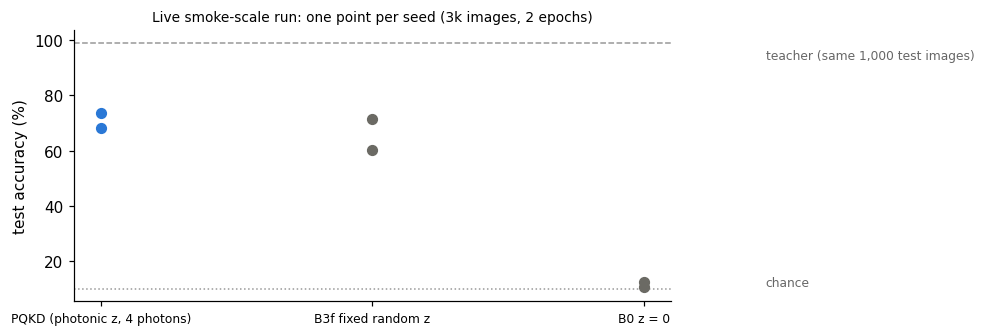

In [9]:
def live_values(name, path):
    values = []
    for seed in LIVE_SEEDS:
        value = live[name][seed]
        for key in path.split("."):
            value = value[key]
        values.append(float(value))
    return values


rows = []
for name in ARMS:
    test = live_values(name, "final_evaluation.test_accuracy")
    zero = live_values(name, "final_evaluation.test_accuracy_zero_feature")
    rows.append([name, " / ".join(f"{v:.2f}" for v in test),
                 " / ".join(f"{t - z:+.1f}" for t, z in zip(test, zero))])
table(["arm (live, smoke-scale)", "test acc % (seed 0 / 1)", "δ = acc(z) − acc(z = 0) in the same model (pp)"], rows)

fig, ax = plt.subplots(figsize=(7, 3.2))
for index, (name, (_, family)) in enumerate(ARMS.items()):
    values = live_values(name, "final_evaluation.test_accuracy")
    ax.scatter([index] * len(values), values, color=COLOURS[family], s=40, zorder=3)
ax.axhline(10, color="0.6", linestyle=":", linewidth=1)
ax.text(len(ARMS) - 0.55, 11, "chance", fontsize=8, color="0.4")
teacher_test = live[next(iter(ARMS))][LIVE_SEEDS[0]]["teacher"]["test_accuracy"]
ax.axhline(teacher_test, color="0.6", linestyle="--", linewidth=1)
ax.text(len(ARMS) - 0.55, teacher_test - 6, "teacher (same 1,000 test images)", fontsize=8, color="0.4")
ax.set_xticks(range(len(ARMS)), list(ARMS), fontsize=8)
ax.set_ylabel("test accuracy (%)")
ax.set_title("Live smoke-scale run: one point per seed (3k images, 2 epochs)", fontsize=9)
plt.show()

**Observation:**
- The student trained with z = 0 stays at chance on both seeds.
- The photonic and the random-z students both learn.
- Each conditioned student also has a large δ when its own z is replaced by zero at test time: about +48 to +61 pp, for photonic and random z alike.
- After only 2 epochs on 3,000 images, PQKD is ahead of random z on both seeds (+8.0 and +2.4 pp). Seeds of the same arm differ by 5–11 pp.

**Inference:**
- A large "photonic gain" δ over z = 0 appears for a **non-photonic** z too.
- δ therefore measures "working conditioning vector vs zeroed kernels", not a photonic contribution.

**Remaining uncertainty:**
- The early-training gap between PQKD and random z is smaller than the seed-to-seed spread, and comes from an unconverged smoke run.
- At full scale (section 8: 3 seeds, 30 epochs, full data) the ordering **reverses**: fixed random z ≥ PQKD on every seed.
- This live run cannot decide the ranking; it only shows that δ is not specific to photonics.

**Claim impact:** claim B's main evidence (Fig. 4's δ) is **weakened**: it is not specific to the photonic source.

## 7. Headline reproduction result (Table 1, MNIST)

**Source.** `results/s4_mnist_complete.json`, generated by `utils/analyze_s4.py` from:
- teacher sweep S1 (3/3 runs);
- the PQKD arm of the baseline sweeps S4 + S4b.

**Setup.**
- 8 photons in alternating input modes, S = 200, EMA on.
- SPSA (a, c) = (0.01, 0.2), chosen on validation data (section 9).
- 30 epochs, seeds 0–2; the paper uses 100 epochs and 5 seeds.

In [10]:
s4 = load_result("s4_mnist_complete.json")
paper = s4["paper_table1_mnist"]
teacher_s1, pqkd = s4["teacher_s1"], s4["arms"]["pqkd"]

rows = []
for label, paper_value, ours, digits in (
    ("teacher val acc %", paper["teacher"]["val_accuracy"], teacher_s1["val_accuracy"], 2),
    ("teacher val CE", paper["teacher"]["val_cross_entropy"], teacher_s1["val_cross_entropy"], 4),
    ("PQKD val acc %", paper["pqkd"]["val_accuracy"], pqkd["val_accuracy"], 2),
    ("PQKD val CE", paper["pqkd"]["val_cross_entropy"], pqkd["val_cross_entropy"], 4),
    ("PQKD train acc %", paper["pqkd"]["train_accuracy"], pqkd["train_accuracy"], 2),
):
    within = abs(ours["mean"] - paper_value[0]) <= paper_value[1]
    rows.append([label, f"{paper_value[0]:.{digits}f} ± {paper_value[1]:.{digits}f}", fmt(ours, digits),
                 " / ".join(f"{v:.{digits}f}" for v in ours["values"]),
                 f"{ours['mean'] - paper_value[0]:+.{digits}f}", "yes" if within else "no"])
rows.append(["overall compression C_x", "1.50", f"{pqkd['compression_overall']['mean']:.3f}", "—", "—", "yes"])
table(["quantity", "paper (n=5, 100 ep)", "reproduced (n=3, 30 ep)", "per seed", "Δ", "within paper s.d.?"], rows)
print(f"test accuracy: teacher (best-val checkpoint) {fmt(teacher_s1['test_accuracy'])} %, "
      f"PQKD (final epoch) {fmt(pqkd['test_accuracy'])} %")

| quantity | paper (n=5, 100 ep) | reproduced (n=3, 30 ep) | per seed | Δ | within paper s.d.? |
|---|---|---|---|---|---|
| teacher val acc % | 99.07 ± 0.13 | 99.03 ± 0.09 | 98.94 / 99.04 / 99.12 | -0.04 | yes |
| teacher val CE | 0.0310 ± 0.0020 | 0.0340 ± 0.0024 | 0.0367 / 0.0324 / 0.0328 | +0.0030 | no |
| PQKD val acc % | 99.09 ± 0.09 | 98.92 ± 0.16 | 98.74 / 98.98 / 99.04 | -0.17 | no |
| PQKD val CE | 0.0300 ± 0.0010 | 0.0337 ± 0.0019 | 0.0358 / 0.0323 / 0.0330 | +0.0037 | no |
| PQKD train acc % | 99.71 ± 0.02 | 99.23 ± 0.04 | 99.25 / 99.25 / 99.19 | -0.48 | no |
| overall compression C_x | 1.50 | 1.502 | — | — | yes |

test accuracy: teacher (best-val checkpoint) 99.29 ± 0.01 %, PQKD (final epoch) 99.13 ± 0.04 %


**Observation:**
- The teacher's validation accuracy matches the paper within its reported spread; its validation cross-entropy is 0.003 higher (about 1.5 paper s.d.).
- PQKD lands 0.17 pp below the paper's validation accuracy, with slightly higher CE and lower train accuracy, at a third of the training budget.
- The compression factor is reproduced exactly.
- On test accuracy, PQKD is 0.16 pp below the teacher.

**Inference:** the Table 1 **trend** reproduces: the 1.5× compressed student stays within about 0.2 pp of the teacher. The remaining gaps are consistent with 30 vs 100 epochs.

**Remaining uncertainty:** budget (30 epochs, 3 seeds) and the unreported SPSA, shot and photon settings.

**Claim impact:** claim A is **trend-reproduced** as stated. Whether this is an *advantage* is the subject of section 8.

## 8. Fair baseline comparison

The paper's comparators cannot test its claims:
- the teacher is 1.5× larger;
- z = 0 is degenerate (section 4b);
- the controls named in its Supplementary Note 5 are not reported.

The baselines below were **predeclared before any run** (`LOG.md`, Fair Baseline Plan). They differ from PQKD only where stated.

| Dimension | B1 dense KD student | B3f fixed random z | B5 classical generator + SPSA |
|---|---|---|---|
| Information and inputs | same images and teacher logits; no conditioning vector | same images, teacher and architecture; z from N(0, I) instead of photonic | same; z = standardise(cos(Gφ + b)) with 45 trainable φ |
| Parameter count | **matched** (−0.5%, section 4a) | **matched** (identical architecture; no θ) | **matched** (dim φ = dim θ = 45) |
| Training data | **matched** (45k train, same split) | **matched** | **matched** |
| Optimisation steps | **matched** (30 epochs, batch 64, Adam 1e-3) | **matched** | **matched**, plus the same 10 SPSA updates per epoch |
| Tuning budget | none beyond paper values (PQKD had a 6-point SPSA grid) | none | **matched**: the same 6-point SPSA grid and rule (section 9) |
| Compute and wall time | 0.94 h/run vs PQKD 1.45 h/run (same laptop, 3 parallel × 4 threads) | 1.13 h/run | 1.34 h/run |
| Evaluation protocol | **matched** (final-epoch test, same seeds and teachers) | **matched** | **matched** |

**Source.** `results/s4_mnist_complete.json` and `results/phase5_comparison.json`. The S4 + S4b merged set has 27/27 runs; the comparison protocol was frozen before the comparison table was generated.

| arm (8-photon PQKD and controls) | trainable params | test acc % | per seed (0/1/2) | paired Δ vs PQKD (pp) | separated? |
|---|---|---|---|---|---|
| PQKD (photonic z, SPSA θ) | 149,439 | 99.13 ± 0.04 | 99.11 / 99.18 / 99.10 | — | — |
| B1 dense KD, same trainable budget | 148,626 | 99.29 ± 0.08 | 99.31 / 99.35 / 99.20 | 0.16 ± 0.05 | yes |
| B2 learned mixing (+33k params) | 182,418 | 99.26 ± 0.06 | 99.25 / 99.33 / 99.21 | 0.13 ± 0.02 | yes |
| B3f fixed random z | 149,394 | 99.18 ± 0.02 | 99.16 / 99.19 / 99.18 | 0.05 ± 0.04 | yes |
| B4 photonic z, θ frozen | 149,394 | 99.14 ± 0.09 | 99.04 / 99.17 / 99.21 | 0.01 ± 0.09 | no |
| B5 classical generator, SPSA | 149,439 | 98.82 ± 0.09 | 98.83 / 98.90 / 98.72 | -0.31 ± 0.06 | yes |
| B6 classical click histograms | 149,394 | 98.48 ± 0.09 | 98.55 / 98.52 / 98.38 | -0.65 ± 0.08 | yes |
| B3r random z redrawn each epoch | 149,394 | 98.15 ± 0.35 | 98.25 / 97.76 / 98.43 | -0.98 ± 0.39 | yes |
| B0 z = 0 (paper control) | 149,394 | 10.81 ± 0.93 | 9.74 / 11.35 / 11.35 | -88.32 ± 0.91 | yes |

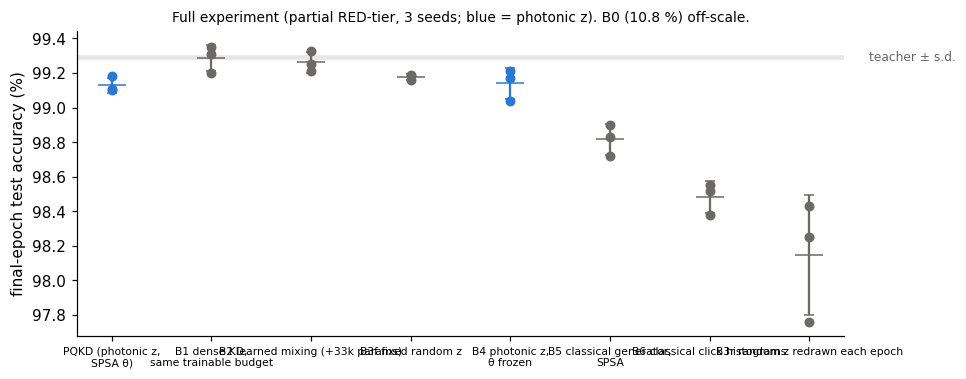

In [11]:
ORDER = ["pqkd", "B1_kd_dense", "B2_dictionary_trainable", "B3f_random_fixed", "B4_fixed_photonic",
         "B5_surrogate", "B6_classical_histogram", "B3r_random_resampled", "B0_zero"]
LABELS = {
    "pqkd": "PQKD (photonic z, SPSA θ)", "B1_kd_dense": "B1 dense KD, same trainable budget",
    "B2_dictionary_trainable": "B2 learned mixing (+33k params)", "B3f_random_fixed": "B3f fixed random z",
    "B4_fixed_photonic": "B4 photonic z, θ frozen", "B5_surrogate": "B5 classical generator, SPSA",
    "B6_classical_histogram": "B6 classical click histograms", "B3r_random_resampled": "B3r random z redrawn each epoch",
    "B0_zero": "B0 z = 0 (paper control)",
}
rows = []
for arm in ORDER:
    entry = s4["arms"][arm]
    paired = s4["paired_vs_pqkd"].get(arm, {}).get("test_accuracy")
    rows.append([
        LABELS[arm], f"{int(entry['trainable_parameters']['mean']):,}", fmt(entry["test_accuracy"]),
        " / ".join(f"{v:.2f}" for v in entry["test_accuracy"]["values"]),
        "—" if paired is None else fmt(paired),
        "—" if paired is None else ("yes" if paired["exceeds_seed_std"] else "no"),
    ])
table(["arm (8-photon PQKD and controls)", "trainable params", "test acc %", "per seed (0/1/2)",
       "paired Δ vs PQKD (pp)", "separated?"], rows)

fig, ax = plt.subplots(figsize=(9, 3.6))
for index, arm in enumerate(ORDER[:-1]):
    values = s4["arms"][arm]["test_accuracy"]["values"]
    family = "photonic" if arm in ("pqkd", "B4_fixed_photonic") else "classical"
    ax.scatter([index] * 3, values, color=COLOURS[family], s=30, zorder=3)
    ax.errorbar(index, np.mean(values), yerr=np.std(values, ddof=1), fmt="_", color=COLOURS[family], markersize=18, capsize=3)
ax.axhspan(teacher_s1["test_accuracy"]["mean"] - teacher_s1["test_accuracy"]["std"],
           teacher_s1["test_accuracy"]["mean"] + teacher_s1["test_accuracy"]["std"], color="0.9", zorder=0)
ax.text(7.6, teacher_s1["test_accuracy"]["mean"], "teacher ± s.d.", fontsize=8, color="0.4", va="center")
ax.set_xticks(range(len(ORDER) - 1), [LABELS[a].replace(", ", ",\n", 1) for a in ORDER[:-1]], fontsize=7)
ax.set_ylabel("final-epoch test accuracy (%)")
ax.set_title("Full experiment (partial RED-tier, 3 seeds; blue = photonic z). B0 (10.8 %) off-scale.", fontsize=9)
plt.show()

**Observation:**
- The dense student with the same trainable budget (B1) beats PQKD on **every** seed (+0.16 ± 0.05 pp).
- A fixed random z (B3f) is at least as good as the photonic z (+0.05 ± 0.04 pp, all three seeds positive).
- Freezing θ (B4) changes nothing (+0.01 ± 0.09 pp).
- The classical sources that *change z during training* are worse than PQKD: B5 (SPSA-updated generator), B6 (sampled histograms) and B3r (redrawn every epoch).

**Inference:**
- The compressed student works because it receives *some* stable conditioning vector, not because the vector is photonic.
- At this parameter budget, the dictionary structure itself is no better than a plain dense student.

**Remaining uncertainty:**
- 3 seeds and 30 epochs.
- Only MNIST, where every arm is close to the ceiling. Fashion-MNIST, where the paper reports PQKD above the teacher, was not run.

**Claim impact:**
- Claim A, as an *advantage* over a fair alternative: **contradicted** on MNIST.
- Claim B: **not supported**.

## 9. Controls and ablations

### 9a. What drives accuracy: the source of z, or its stability?

**Source.** `results/s4_feature_stability.json`, from `utils/feature_stability.py` over the saved per-epoch feature traces of every conditioned S4 run.

The quantity is the mean relative epoch-to-epoch change of the z actually used in training.

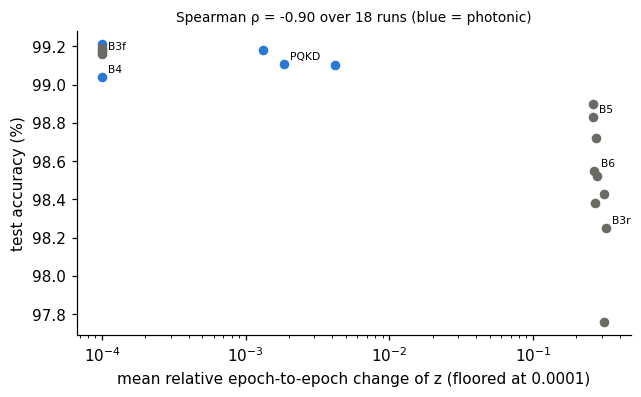

In [12]:
stability = load_result("s4_feature_stability.json")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
floor = 1e-4
for row in stability["rows"]:
    if row["arm"] == "B0_zero":
        continue
    family = "photonic" if row["arm"] in ("pqkd", "B4_fixed_photonic") else "classical"
    steps = [max(run["used_step_mean"], floor) for run in row["runs"]]
    accuracies = [run["test_accuracy"] for run in row["runs"]]
    ax.scatter(steps, accuracies, color=COLOURS[family], s=28)
    ax.annotate(row["arm"].split("_")[0] if row["arm"] != "pqkd" else "PQKD", (steps[0], accuracies[0]),
                fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel(f"mean relative epoch-to-epoch change of z (floored at {floor:g})")
ax.set_ylabel("test accuracy (%)")
ax.set_title(f"Spearman ρ = {stability['spearman_step_vs_test_accuracy']:.2f} over {stability['n_runs']} runs "
             "(blue = photonic)", fontsize=9)
plt.show()

**Observation:** accuracy decreases monotonically with how much z changes between epochs (ρ = −0.90). Photonic and classical sources sit on the same curve.

**Inference:** stability, not photonic origin, is the variable that matters. In the paper's θ ≈ 0 regime the photonic z is almost constant, which is why PQKD behaves like a fixed random vector.

**Claim impact:** this supports the alternative explanation for claim B.

### 9b. Hyperparameter selection used validation data only

The paper does not report the SPSA step sizes. One predeclared 6-point grid was run for the photonic generator (S2) and the **same** grid for the classical generator B5 (S3), giving equal tuning budgets.
- Selection minimised the final validation KD proxy; test accuracy is shown for transparency but was not used.
- The runs used seed 0 and 10 epochs; they are selection evidence only.

**Source.** `results/s2_spsa_grid_photonic.json`, `results/s3_spsa_grid_surrogate.json`.

In [13]:
for name in ("s2_spsa_grid_photonic.json", "s3_spsa_grid_surrogate.json"):
    sweep = load_result(name)
    rows = [[row["candidate"], f"{row['final_epoch.proxy_objective']['mean']:.4f}",
             f"{row['final_epoch.parameter_norm']['mean']:.2f}", f"{row['final_evaluation.test_accuracy']['mean']:.2f}"]
            for row in sweep["rows"]]
    display(Markdown(f"**{sweep['sweep_id']}**: {sweep['coverage']}; selected {sweep['selected_candidates']}; "
                     f"tied within {sweep['selection']['tie_tolerance']}: {sweep['tied_within_tolerance']}"))
    table(["candidate", "val KD proxy (selection metric, ↓)", "‖parameters‖", "test acc % (not used)"], rows)

**S2_spsa_grid_photonic**: COMPLETE SWEEP; selected ['a0.01_c0.2']; tied within 0.002: ['a0.01_c0.2']

| candidate | val KD proxy (selection metric, ↓) | ‖parameters‖ | test acc % (not used) |
|---|---|---|---|
| a0.01_c0.05 | 0.1624 | 0.31 | 98.80 |
| a0.01_c0.2 | 0.1425 | 1.08 | 98.78 |
| a0.05_c0.05 | 0.2892 | 21.07 | 98.37 |
| a0.05_c0.2 | 0.1536 | 10.05 | 98.86 |
| a0.2_c0.05 | 0.1926 | 15.75 | 98.44 |
| a0.2_c0.2 | 0.2038 | 21.07 | 98.61 |

**S3_spsa_grid_surrogate**: COMPLETE SWEEP; selected ['a0.05_c0.2']; tied within 0.002: ['a0.05_c0.2', 'a0.2_c0.05']

| candidate | val KD proxy (selection metric, ↓) | ‖parameters‖ | test acc % (not used) |
|---|---|---|---|
| a0.01_c0.05 | 0.1610 | 15.67 | 98.75 |
| a0.01_c0.2 | 0.1507 | 13.07 | 98.61 |
| a0.05_c0.05 | 0.1529 | 16.74 | 98.79 |
| a0.05_c0.2 | 0.1371 | 16.94 | 98.69 |
| a0.2_c0.05 | 0.1378 | 21.07 | 98.81 |
| a0.2_c0.2 | 0.1466 | 21.07 | 98.66 |

**Observation:**
- For the photonic generator, large steps with a small perturbation drive every angle to the ±π clip: ‖θ‖ = π√45 = 21.07, the worst objective.
- The selected (a, c) = (0.01, 0.2) keeps θ near the identity (‖θ‖ ≈ 1).
- The classical grid had a tie inside tolerance, which the predeclared rule broke toward the smaller a.

**Claim impact:** the paper's results depend on unreported SPSA settings that decide whether θ ever leaves the deterministic regime. This is a reproducibility gap, not a test of the claim.

## 10. Robustness and uncertainty

All stochastic comparisons are **paired per seed**: same teacher, same data order, same seed.

**Rule (predeclared).** An arm is "separated" from its reference only if |mean paired Δ| exceeds the s.d. of the paired Δ.

**What is shown.**
- The forest plot shows every comparison the Phase 5 protocol froze, with per-seed points.
- The table checks that the conclusions do not depend on choosing test over validation.

**Source.** `results/phase5_comparison.json`, `results/s4_mnist_complete.json`.

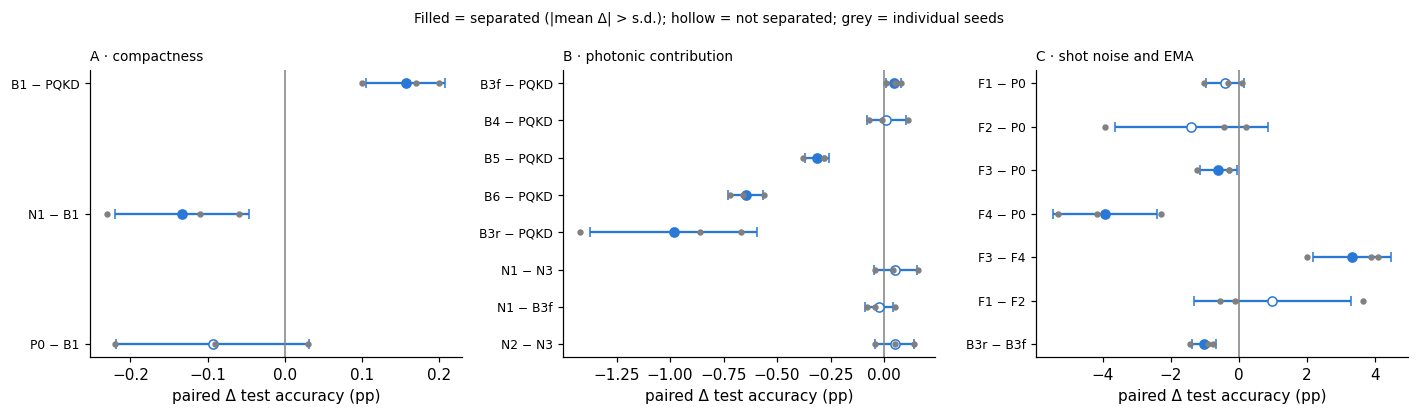

| arm vs PQKD (S4) | Δ test acc (pp) | Δ val acc (pp) | sign test vs val |
|---|---|---|---|
| B1 dense KD, same trainable budget | 0.16 ± 0.05 | 0.25 ± 0.12 | same |
| B2 learned mixing (+33k params) | 0.13 ± 0.02 | 0.13 ± 0.22 | same |
| B3f fixed random z | 0.05 ± 0.04 | 0.03 ± 0.18 | same |
| B4 photonic z, θ frozen | 0.01 ± 0.09 | -0.02 ± 0.10 | differs |
| B5 classical generator, SPSA | -0.31 ± 0.06 | -0.48 ± 0.31 | same |
| B6 classical click histograms | -0.65 ± 0.08 | -0.79 ± 0.05 | same |
| B3r random z redrawn each epoch | -0.98 ± 0.39 | -1.14 ± 0.40 | same |

In [14]:
comparison = load_result("phase5_comparison.json")
panels = [("A", "A · compactness"), ("B", "B · photonic contribution"), ("C", "C · shot noise and EMA")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (claim, title) in zip(axes, panels):
    entries = [e for e in comparison["paired"] if e["claim"] == claim]
    for row, entry in enumerate(reversed(entries)):
        diff = entry["test_accuracy_difference"]
        ax.errorbar(diff["mean"], row, xerr=diff["std"], fmt="o", color=COLOURS["photonic"],
                    markerfacecolor=COLOURS["photonic"] if diff["separated"] else "white", capsize=3)
        ax.scatter(diff["values"], [row] * len(diff["values"]), color="0.5", s=10, zorder=3)
    labels = [f"{e['arm'].split('_')[0]} − {e['reference'].split('_')[0]}".replace("pqkd", "PQKD") for e in reversed(entries)]
    ax.set_yticks(range(len(entries)), labels, fontsize=8)
    ax.axvline(0, color="0.5", linewidth=1)
    ax.set_title(title, fontsize=9, loc="left")
    ax.set_xlabel("paired Δ test accuracy (pp)")
fig.suptitle("Filled = separated (|mean Δ| > s.d.); hollow = not separated; grey = individual seeds", fontsize=9)
plt.tight_layout()
plt.show()

rows = []
for arm in ORDER[1:-1]:
    paired = s4["paired_vs_pqkd"][arm]
    rows.append([LABELS[arm], fmt(paired["test_accuracy"]), fmt(paired["val_accuracy"]),
                 "same" if np.sign(paired["test_accuracy"]["mean"]) == np.sign(paired["val_accuracy"]["mean"]) else "differs"])
table(["arm vs PQKD (S4)", "Δ test acc (pp)", "Δ val acc (pp)", "sign test vs val"], rows)

**Observation:**
- Every decisive comparison has the same sign on all three seeds:
  - dense student − PQKD;
  - fixed random z − PQKD;
  - 25 shots without EMA − P0;
  - EMA − no EMA at 25 shots.
- Validation, which SPSA optimises for PQKD, gives the same sign as test for every arm except B4, whose difference is about zero on both. B1's lead over PQKD is even larger on validation (+0.25 vs +0.16 pp), so the test/validation choice does not favour the conclusion.

**Remaining uncertainty:** n = 3 seeds gives weak statistics. The separation rule is a conservative screen, not a significance test.

**Claim impact:** none of the conclusions rests on a single seed or on the test/validation choice.

## 11. Photonic assessment: MerLin adaptation at 4 photons

The paper is already photonic, so running it in MerLin is only a simulator substitution. The adaptation asks two further questions on the same circuit:
- **Paper-faithful, mixing regime (F1–F4).** θ starts at U[−π, π], so the sampler is genuinely stochastic; S ∈ {200, 25} with EMA on or off. This is where the shot-noise and EMA claims (C) can act.
- **MerLin-native (N1–N2, simulation only).**
  - z is the *exact* output distribution;
  - θ is trained by autograd jointly with the student (no shots, no SPSA);
  - N3 is a classical 45-parameter generator trained the same way;
  - P0 is the paper-faithful PQKD at 4 photons.

**Source.** `results/s6_mnist_4ph_complete.json`, sweep S6 plus resumes 1–3, 24/24 runs. Same teachers, seeds and budget as section 8. Simulated, 4 photons; 8 photons was too costly on CPU.

| arm (4 photons, simulated) | test acc % | per seed | test acc with one fresh z, per seed | ‖θ‖ final |
|---|---|---|---|---|
| P0 PQKD, θ₀=0, S=200, EMA | 99.19 ± 0.09 | 99.09 / 99.26 / 99.23 | 99.1 / 99.3 / 99.2 | 0.93 ± 0.77 |
| F1 mixing θ, S=200, EMA | 98.78 ± 0.49 | 99.18 / 98.24 / 98.92 | 99.1 / 21.8 / 13.7 | 13.48 ± 1.23 |
| F2 mixing θ, S=200, no EMA | 97.80 ± 2.19 | 99.30 / 98.81 / 95.28 | 99.3 / 98.9 / 94.0 | 13.06 ± 0.87 |
| F3 mixing θ, S=25, EMA | 98.58 ± 0.63 | 97.85 / 98.96 / 98.93 | 10.9 / 10.7 / 15.8 | 18.36 ± 1.86 |
| F4 mixing θ, S=25, no EMA | 95.26 ± 1.60 | 93.76 / 95.09 / 96.94 | 14.5 / 33.2 / 96.0 | 17.54 ± 5.11 |
| N1 exact z, autograd θ, θ₀ random | 99.15 ± 0.08 | 99.08 / 99.24 / 99.14 | 99.1 / 99.2 / 99.1 | 13.18 ± 0.58 |
| N2 exact z, autograd θ, θ₀ = 0 | 99.15 ± 0.08 | 99.08 / 99.13 / 99.24 | 99.1 / 99.1 / 99.2 | 0.00 ± 0.00 |
| N3 classical generator, autograd | 99.10 ± 0.02 | 99.12 / 99.08 / 99.10 | 99.1 / 99.1 / 99.1 | 12.16 ± 1.04 |

| comparison | paired Δ test acc (pp) | separated? |
|---|---|---|
| N1 − N3 | 0.05 ± 0.10 | no |
| N1 − B3f | -0.02 ± 0.07 | no |
| N1 − B1 | -0.13 ± 0.09 | yes |
| F4 − P0 | -3.93 ± 1.53 | yes |
| F3 − F4 | 3.32 ± 1.15 | yes |
| P0 − pqkd | 0.06 ± 0.08 | no |

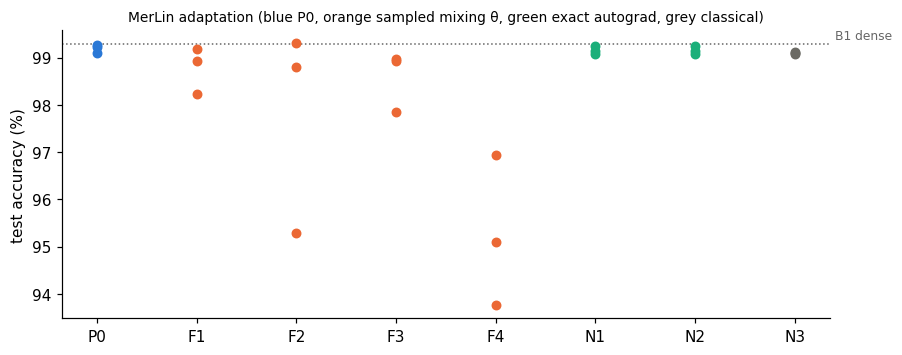

In [15]:
s6 = load_result("s6_mnist_4ph_complete.json")
S6_ARMS = [("P0_pqkd_theta0", "P0 PQKD, θ₀=0, S=200, EMA", "photonic"),
           ("F1_mixing_s200_ema", "F1 mixing θ, S=200, EMA", "sampled"),
           ("F2_mixing_s200_noema", "F2 mixing θ, S=200, no EMA", "sampled"),
           ("F3_mixing_s25_ema", "F3 mixing θ, S=25, EMA", "sampled"),
           ("F4_mixing_s25_noema", "F4 mixing θ, S=25, no EMA", "sampled"),
           ("N1_native_grad_random", "N1 exact z, autograd θ, θ₀ random", "exact"),
           ("N2_native_grad_zero", "N2 exact z, autograd θ, θ₀ = 0", "exact"),
           ("N3_surrogate_grad", "N3 classical generator, autograd", "classical")]
rows = []
for arm, label, _ in S6_ARMS:
    entry = s6["arms"][arm]
    rows.append([label, fmt(entry["test_accuracy"]), " / ".join(f"{v:.2f}" for v in entry["test_accuracy"]["values"]),
                 " / ".join(f"{v:.1f}" for v in entry["test_accuracy_fresh_feature"]["values"]), fmt(entry["theta_norm"])])
table(["arm (4 photons, simulated)", "test acc %", "per seed", "test acc with one fresh z, per seed", "‖θ‖ final"], rows)

key_pairs = {(e["arm"], e["reference"]): e["test_accuracy"] for e in s6["paired"]}
table(["comparison", "paired Δ test acc (pp)", "separated?"], [
    [f"{a.split('_')[0]} − {r.split('_')[0]}", fmt(key_pairs[(a, r)]), "yes" if key_pairs[(a, r)]["exceeds_seed_std"] else "no"]
    for a, r in (("N1_native_grad_random", "N3_surrogate_grad"), ("N1_native_grad_random", "B3f_random_fixed"),
                 ("N1_native_grad_random", "B1_kd_dense"), ("F4_mixing_s25_noema", "P0_pqkd_theta0"),
                 ("F3_mixing_s25_ema", "F4_mixing_s25_noema"), ("P0_pqkd_theta0", "pqkd"))
])

fig, ax = plt.subplots(figsize=(9, 3.4))
for index, (arm, label, family) in enumerate(S6_ARMS):
    values = s6["arms"][arm]["test_accuracy"]["values"]
    ax.scatter([index] * 3, values, color=COLOURS[family], s=30, zorder=3)
ax.axhline(s4["arms"]["B1_kd_dense"]["test_accuracy"]["mean"], color="0.4", linestyle=":", linewidth=1)
ax.text(7.4, s4["arms"]["B1_kd_dense"]["test_accuracy"]["mean"] + 0.1, "B1 dense", fontsize=8, color="0.4")
ax.set_xticks(range(len(S6_ARMS)), [label.split(" ", 1)[0] for _, label, _ in S6_ARMS])
ax.set_ylabel("test accuracy (%)")
ax.set_title("MerLin adaptation (blue P0, orange sampled mixing θ, green exact autograd, grey classical)", fontsize=9)
plt.show()

**Observation:**
- With exact probabilities and true gradients, the photonic generator (N1) equals the classical generator (N3) and a fixed random z. It is below the dense student.
- θ trained from 0 (N2) never moves.
- In the mixing regime, fewer shots cost accuracy (F4 − P0 = −3.93 ± 1.53 pp), and EMA recovers most of it at 25 shots (+3.32 ± 1.15 pp, all seeds). No sampled arm beats P0.
- Evaluating with one fresh, unsmoothed z draw breaks most students trained with EMA or with 25 shots. Only F2 (200 shots, no EMA, which trains on the noise) is robust.
- 4 vs 8 photons makes no difference for PQKD.

**Inference:**
- The photonic module maps cleanly to MerLin, but it adds no measurable value even under ideal (exact-gradient, noise-free) conditions.
- The shot and EMA effects the paper reports are real. They describe the *cost* of a noisy conditioning vector, which a classical redrawn z shares (−1.03 ± 0.36 pp, section 10).

**Remaining uncertainty:** 4 photons only; no hardware noise model; MNIST only.

**Claim impact:**
- Claim C: **partially supported**, direction only, and not photonic-specific.
- Claim B: **not supported**, now also with exact gradients.

**Hardware-aware settings (all S6 arms):**

| Field | Value |
|---|---|
| Computation space | FOCK |
| Detector model | ideal threshold, clicks = 1[n > 0] |
| Photons / modes | 4 / 16, input [1,0,0,0]×4, 3,876 Fock states |
| Encoding | none (θ is the only circuit parameter) |
| Measurement | `probs(FOCK)` → two 256-bin marginal histograms |
| Postselection | none |
| Simulator or QPU | MerLin CPU simulator, float64, lossless; pre-release build `0.5.0.dev0` with the 0.4.2 API |
| Shots | 200 (P0, F1, F2), 25 (F3, F4), exact (N1, N2) |
| Wall-clock | 1.5–1.8 h per 30-epoch run |
| Seeds | 0–2 |

## 12. Conclusion

What each evidence level shows:
- **The software executes:** yes (sections 4–6; 65 unit tests in `tests/`).
- **The method solves the task:** yes; PQKD students reach 99.1–99.2 % test accuracy (sections 7, 11).
- **The paper's metric reproduces:**
  - teacher validation accuracy, the compression factor and the size of Fig. 4's δ match; teacher CE is 0.003 higher;
  - PQKD's validation accuracy is 0.17 pp lower at a third of the budget (section 7).
- **The paper's explanation survives controls:** **no**. Its gain appears for a non-photonic z (sections 4b, 6), and accuracy follows the stability of z, not its photonic origin (section 9a).
- **The method beats a fair baseline:** **no**. A dense student at the same budget is better, and a fixed random z is as good or better (section 8).

| | Conclusion | Evidence |
|---|---|---|
| 1. What reproduced | Table 1 trend on MNIST: teacher validation accuracy, C_x = 1.50, PQKD within about 0.2 pp of the teacher. The size of Fig. 4's δ. The direction of the shot-noise and EMA effects in a stochastic θ regime. | §7, §6, §11 |
| 2. What did not reproduce | The photonic contribution: fixed random z ≥ PQKD; θ frozen = PQKD; exact-gradient photonic = classical generator. PQKD's advantage over a fair same-budget student: dense KD is better on every seed. | §8, §9a, §10, §11 |
| 3. What remains unresolved | Whether the conclusions change at 100 epochs and 5 seeds, at 8 photons, or on harder data. The paper's photonic Δ, whose units are undefined. | §7, §9b |
| 4. What was not attempted | Fashion-MNIST and CIFAR-10 (Table 1), Table 2 / Fig. 2 compression frontier, the full Fig. 4 shot sweep (only S ∈ {25, 200}), EMA variance ratio (Supp. Fig. S1), noise robustness, hardware. | README, Limitations |
| 5. Reproduction verdict | **Partially reproduced:** trend reproduced; claims A (as an advantage) and B **unsupported**; claim C **partially supported** and not photonic-specific. Partial RED-tier evidence (MNIST, 30 epochs, 3 seeds). | §7–§10 |
| 6. Photonic verdict | **MERLIN_IMPLEMENTATION** (simulated, reduced scope). The mapping is clean, but the photonic generator gives no measurable benefit, even with exact gradients. No quantum or photonic advantage is supported. | §11 |

**Limitations:**
- CPU-only, reduced budget (30 vs 100 epochs, 3 vs 5 seeds), MNIST only.
- Unreported SPSA, shot and photon settings were replaced by predeclared choices.
- Simulation only: MerLin instead of the paper's CUDA-Q ORCA simulator, and no hardware.
- The live experiment in section 6 is smoke-scale; the full numbers come from committed result files.

In [16]:
print(f"Notebook runtime (fresh kernel, CPU): {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

Notebook runtime (fresh kernel, CPU): 3.9 min
